In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split

In [4]:
df = pd.read_csv("4_sports_college_athletics_money/4_college_athletics_eada_2024_25_cleaned.csv")
print(df.shape)
df.head()

(356, 34)


,unitid,school,city,state,division,sector,students_men,students_women,students_total,athletes_men,...,has_football,football_revenue,football_expenses,football_profit,football_makes_money,mens_bball_revenue,mens_bball_expenses,womens_bball_revenue,womens_bball_expenses,ncaa_d1
0,100654,Alabama A & M University,Normal,AL,NCAA Division I-FCS,"Public, 4-year or above",2375,3293,5668,294,...,1,5099251.0,4382334.0,716917.0,1.0,1591243,1235045,1293631,1183091,1
1,100663,University of Alabama at Birmingham,Birmingham,AL,NCAA Division I-FBS,"Public, 4-year or above",3484,6051,9535,228,...,1,14442335.0,13162064.0,1280271.0,1.0,5349479,5003621,2577756,2435278,1
2,100724,Alabama State University,Montgomery,AL,NCAA Division I-FCS,"Public, 4-year or above",1177,2066,3243,212,...,1,4937810.0,4937810.0,0.0,0.0,1131147,1131147,1129829,1129829,1
3,100751,The University of Alabama,Tuscaloosa,AL,NCAA Division I-FBS,"Public, 4-year or above",13553,17420,30973,320,...,1,146325227.0,81502191.0,64823036.0,1.0,24406961,15230030,5433584,5433584,1
4,100858,Auburn University,Auburn,AL,NCAA Division I-FBS,"Public, 4-year or above",12326,12851,25177,282,...,1,121408732.0,58724402.0,62684330.0,1.0,26568984,20535097,847898,5812213,1


In [5]:
single_row = df[df['unitid'] == 100654][['athletic_aid_men', 'athletic_aid_women', 'recruiting_men', 'recruiting_women', 'head_coach_pay_mens_teams', 'head_coach_pay_womens_teams', 'football_expenses', 'mens_bball_expenses', 'womens_bball_expenses', 'total_revenue']]
print(single_row)

second_row = df[df['unitid'] == 100654][['total_expenses', 'total_revenue']]

   athletic_aid_men  athletic_aid_women  recruiting_men  recruiting_women  \
0           2655847             1895018           64002             52365   

   head_coach_pay_mens_teams  head_coach_pay_womens_teams  football_expenses  \
0                     135748                        63991          4382334.0   

   mens_bball_expenses  womens_bball_expenses  total_revenue  
0              1235045                1183091       13021239  


In [6]:
second_row = df[df['unitid'] == 100654][['total_expenses', 'total_revenue']]
print(second_row)

   total_expenses  total_revenue
0        13021239       13021239


In [7]:
df[['total_expenses', 'total_revenue']].describe()

,total_expenses,total_revenue
count,3.560000e+02,3.560000e+02
mean,5.818716e+07,5.956159e+07
std,6.027825e+07,6.283230e+07
min,5.091720e+06,5.091720e+06
25%,2.034188e+07,2.055358e+07
50%,3.285698e+07,3.302172e+07
75%,5.887651e+07,5.942218e+07
max,2.952659e+08,3.431068e+08


Modeling Start

In [ ]:
#filling in missing values for football_expenses with 0, as schools without football spend 0 on it. 
df['football_expenses'] = df['football_expenses'].fillna(0)

#this results in about 100 new values of 0 for football_expenses, which ensures there are no na values in variable/model calculation

In [15]:
#These are new variables created for the model

#this is the total women and men's expenses, a sum of all the expense columns PRESENT in the dataset
df['women_spend'] = df['womens_bball_expenses'] + df['head_coach_pay_womens_teams'] + df['athletic_aid_women'] + df['recruiting_women']
df['men_spend'] = df['football_expenses'] + df['mens_bball_expenses'] + df['head_coach_pay_mens_teams'] + df['athletic_aid_men'] + df['recruiting_men']

#this is the same as men_spend, but without football expenses, which is a major outlier in the dataset and skews the results of the model
df['men_spend_no_fb'] = df['mens_bball_expenses'] + df['head_coach_pay_mens_teams'] + df['athletic_aid_men'] + df['recruiting_men']

#this is the sum of the total expenses for both men and women, which is used to calculate the share of women's spending in relation to the total spending
#using this variable instead of total_expenses because total_expenses wouldn't be representative of the spending on sports present in the dataset 
df['adj_total_expenses'] = df['women_spend'] + df['men_spend']
df['adj_total_expenses_no_fb'] = df['women_spend'] + df['men_spend_no_fb'] #football expenses are removed from the calculation of the adjusted total expenses


In [16]:
#percentage of women's spending in relation to the total spending, presented as a decimal(0-1)
df['women_share'] = df['women_spend'] / df['adj_total_expenses']
df['women_share_no_fb'] = df['women_spend'] / df['adj_total_expenses_no_fb']

#the difference between the percentage of women's spending in relation to the total spending and the percentage of women athletes in relation to the total athletes, presented as a decimal(0-1)
df['gap'] = df['women_share'] - (df["pct_women_athletes"] / 100)
df['gap_no_fb'] = df['women_share_no_fb'] - (df["pct_women_athletes"] / 100) #football expenses are removed from the calculation of the gap

print(df[['unitid', 'women_spend', 'men_spend', 'adj_total_expenses', 'women_share', 'women_share_no_fb', 'gap', 'gap_no_fb']].head())

   unitid  women_spend    men_spend  adj_total_expenses  women_share  \
0  100654      3194465    8472976.0          11667441.0     0.273793   
1  100663      6386397   23795483.0          30181880.0     0.211597   
2  100724      2824708    8219557.0          11044265.0     0.255762   
3  100751     14600628  112885801.0         127486429.0     0.114527   
4  100858     15808341   95620251.0         111428592.0     0.141870   

   women_share_no_fb       gap  gap_no_fb  
0           0.438493 -0.136207   0.028493  
1           0.375233 -0.240403  -0.076767  
2           0.462577 -0.000238   0.206577  
3           0.317514 -0.406473  -0.203486  
4           0.299945 -0.350130  -0.192055  


In [17]:
no_fb_test = df[df['unitid'] == 106245][['women_share', 'women_share_no_fb', 'gap', 'gap_no_fb']]
print(no_fb_test)

    women_share  women_share_no_fb       gap  gap_no_fb
14     0.446176           0.446176 -0.010824  -0.010824


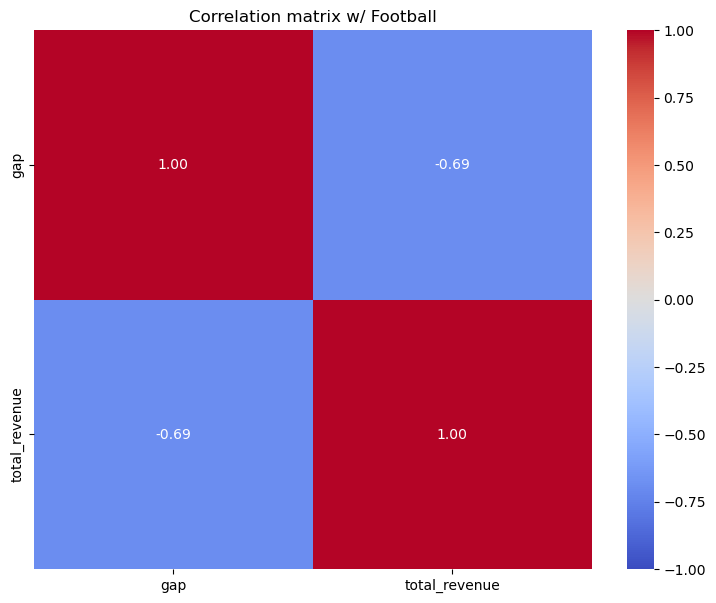

In [23]:
corr = df[["gap"] + ["total_revenue"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix w/ Football")
plt.show()

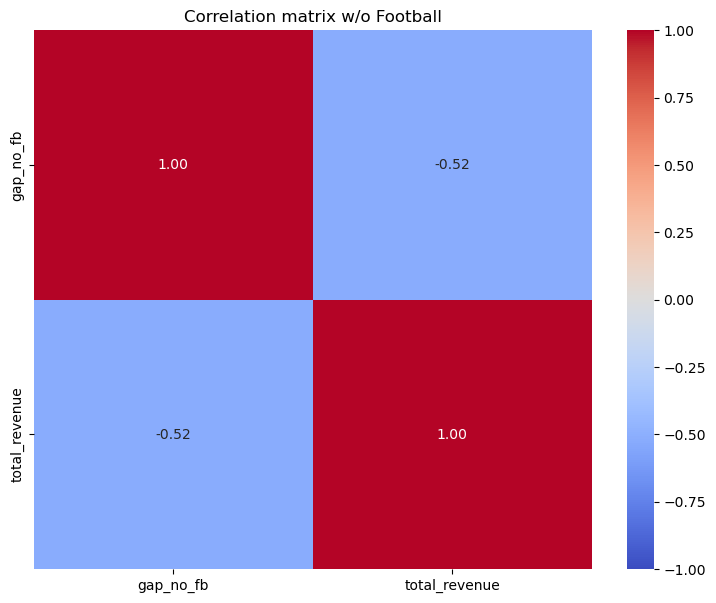

In [25]:
corr = df[["gap_no_fb"] + ["total_revenue"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix w/o Football")
plt.show()

In [ ]:
model_log = smf.ols('gap ~ np.log(total_revenue)', data=df).fit()
print(model_log.summary())

                            OLS Regression Results                            
Dep. Variable:                    gap   R-squared:                       0.590
Model:                            OLS   Adj. R-squared:                  0.589
Method:                 Least Squares   F-statistic:                     474.6
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           7.79e-66
Time:                        14:28:04   Log-Likelihood:                 409.78
No. Observations:                 332   AIC:                            -815.6
Df Residuals:                     330   BIC:                            -808.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 1.53